# 02. Tiền xử lý, xây mô hình và đánh giá
Notebook này đi qua toàn bộ phần *machine learning*:

1. Chia dữ liệu train/test (làm **trước** mọi thứ khác để tránh rò rỉ dữ liệu)
2. Xây pipeline tiền xử lý + feature engineering
3. So sánh 6 mô hình bằng cross-validation
4. Tinh chỉnh (tuning) mô hình tốt nhất
5. Chọn ngưỡng quyết định
6. Đánh giá **một lần duy nhất** trên tập test
7. Phân tích lỗi và lưu mô hình để deploy

⏱️ **Thời gian chạy:** khoảng 10 phút trên máy 2 lõi (phần lớn là bước tuning ở mục 4).

**Đầu ra:** `model/fraud_pipeline.joblib`, `model/metadata.json`, `results.json` và các hình 07–10.

In [2]:
import json
import os
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    PrecisionRecallDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

from fraud_features import CATEGORICAL, RAW_COLUMNS, add_features  # hàm dùng chung với app deploy

%matplotlib inline
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)
os.makedirs("model", exist_ok=True)

SEED = 42
N_JOBS = max(1, os.cpu_count() or 2)
results = {"seed": SEED}   # gom kết quả để lưu ra results.json

## 1. Đọc dữ liệu và chia train/test
- Chỉ giữ 6 cột thô: `type`, `amount`, `oldbalanceOrg`, `newbalanceOrig`, `oldbalanceDest`, `newbalanceDest`. Các cột `nameOrig`, `nameDest`, `isFlaggedFraud`, `step` bị bỏ theo kết luận EDA.
- Chia **80% train / 20% test**, có `stratify` để cả hai tập giữ cùng tỷ lệ gian lận.
- Tập test sẽ được "khóa lại" và chỉ dùng **một lần** ở mục 6.

In [4]:
df = pd.read_csv("Synthetic_Financial_datasets_log.csv", encoding="utf-8-sig")
y = df["isFraud"].astype(int)
X = df[RAW_COLUMNS]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)

results["split"] = {
    "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "fraud_train": int(y_train.sum()), "fraud_test": int(y_test.sum()),
    "fraud_rate_train": float(y_train.mean()), "fraud_rate_test": float(y_test.mean()),
}
neg_pos = float((y_train == 0).sum() / (y_train == 1).sum())
results["neg_pos_ratio_train"] = neg_pos
print(results["split"])
print("Tỷ lệ bình thường : gian lận trong train =", round(neg_pos), ": 1")

{'n_train': 5090096, 'n_test': 1272524, 'fraud_train': 6570, 'fraud_test': 1643, 'fraud_rate_train': 0.0012907418642005967, 'fraud_rate_test': 0.0012911347840983745}
Tỷ lệ bình thường : gian lận trong train = 774 : 1


## 2. Feature engineering và pipeline tiền xử lý
Hàm `add_features` (trong file `fraud_features.py`) tạo 4 đặc trưng mới từ phát hiện ở EDA. Ví dụ trên 5 dòng đầu của tập train:

In [5]:
display(add_features(X_train.head()))

,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,errorBalanceOrig,errorBalanceDest,origEmptied,destEmpty
292779,PAYMENT,9914.74,44248.00,34333.26,0.00,0.00,0.00,9914.74,0,1
499763,PAYMENT,6854.53,0.00,0.00,0.00,0.00,6854.53,6854.53,0,1
2970411,CASH_OUT,361211.80,0.00,0.00,489745.16,850956.95,361211.80,0.01,0,0
3137549,PAYMENT,7083.51,0.00,0.00,0.00,0.00,7083.51,7083.51,0,1
1500682,CASH_IN,218019.51,13045685.58,13263705.09,2438123.98,2220104.47,436039.02,436039.02,0,0


Sau đó ta ghép mọi bước vào **một `Pipeline`**: tạo đặc trưng → one-hot cho `type` → chuẩn hóa số → mô hình.

**Vì sao gói tất cả vào pipeline?**
- Khi cross-validation, các bước tiền xử lý chỉ được "học" (fit) trên phần train của từng fold → không rò rỉ dữ liệu.
- Khi deploy, ta lưu nguyên pipeline nên lúc dự đoán chắc chắn làm đúng như lúc huấn luyện.

In [6]:
def make_pre():
    num_cols = [c for c in add_features(X.head(5)).columns if c not in CATEGORICAL]
    ct = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
        ("num", StandardScaler(), num_cols),
    ])
    return [("features", FunctionTransformer(add_features, validate=False)), ("pre", ct)]


def sk_pipe(clf):
    return Pipeline(make_pre() + [("clf", clf)])


def smote_pipe(clf):
    # SMOTE chỉ áp dụng lên phần train của mỗi fold (imblearn Pipeline lo việc này)
    return ImbPipeline(make_pre() + [("smote", SMOTE(sampling_strategy=0.1, random_state=SEED, k_neighbors=5)),
                                     ("clf", clf)])


models = {
    "Dummy (always 0)": sk_pipe(DummyClassifier(strategy="most_frequent")),
    "Decision Tree": sk_pipe(DecisionTreeClassifier(class_weight="balanced", max_depth=8, random_state=SEED)),
    "Logistic Regression": sk_pipe(LogisticRegression(class_weight="balanced", max_iter=1000)),
    "Random Forest": sk_pipe(RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                                                    min_samples_leaf=2, n_jobs=N_JOBS, random_state=SEED)),
    "XGBoost": sk_pipe(XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, scale_pos_weight=neg_pos,
                                     eval_metric="aucpr", n_jobs=N_JOBS, random_state=SEED)),
    "Logistic Regression + SMOTE": smote_pipe(LogisticRegression(max_iter=1000)),
}
print("Đã tạo", len(models), "pipeline:", list(models))

Đã tạo 6 pipeline: ['Dummy (always 0)', 'Decision Tree', 'Logistic Regression', 'Random Forest', 'XGBoost', 'Logistic Regression + SMOTE']


## 3. So sánh mô hình bằng 5-fold cross-validation (chỉ trên tập train)
Dữ liệu train được chia 5 phần giữ nguyên tỷ lệ gian lận; lần lượt dùng 4 phần để học và 1 phần để chấm điểm.

**Cách đọc các metric:**
- **Recall**: bắt được bao nhiêu % vụ gian lận thật.
- **Precision**: trong số bị báo gian lận, bao nhiêu % là thật.
- **PR-AUC**: điểm tổng hợp Precision và Recall qua mọi ngưỡng, **metric chính** của bài này.
- Accuracy chỉ để so sánh và cho thấy nó đánh lừa như thế nào.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1",
           "pr_auc": "average_precision", "roc_auc": "roc_auc"}

cv_rows = []
for name, model in models.items():
    t0 = time.time()
    s = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    row = {"model": name}
    for k in scoring:
        row[k + "_mean"] = float(np.mean(s["test_" + k]))
        row[k + "_std"] = float(np.std(s["test_" + k]))
    row["seconds"] = round(time.time() - t0, 1)
    cv_rows.append(row)
    print(f"{name:30s} PR-AUC={row['pr_auc_mean']:.4f}  recall={row['recall_mean']:.3f}  "
          f"precision={row['precision_mean']:.3f}  F1={row['f1_mean']:.3f}  acc={row['accuracy_mean']:.4f}  ({row['seconds']}s)")

results["cv_baseline"] = cv_rows
cv_df = pd.DataFrame(cv_rows)
cv_df[["model", "pr_auc_mean", "recall_mean", "precision_mean", "f1_mean", "accuracy_mean", "seconds"]].round(4)

Dummy (always 0)               PR-AUC=0.0013  recall=0.000  precision=0.000  F1=0.000  acc=0.9987  (13.4s)
Decision Tree                  PR-AUC=0.9943  recall=0.996  precision=0.762  F1=0.850  acc=0.9995  (158.0s)
Logistic Regression            PR-AUC=0.7338  recall=0.992  precision=0.034  F1=0.066  acc=0.9640  (82.3s)
Random Forest                  PR-AUC=0.9968  recall=0.995  precision=1.000  F1=0.997  acc=1.0000  (1213.1s)
XGBoost                        PR-AUC=0.9969  recall=0.996  precision=0.926  F1=0.959  acc=0.9999  (89.1s)
Logistic Regression + SMOTE    PR-AUC=0.7470  recall=0.854  precision=0.247  F1=0.383  acc=0.9964  (42.4s)


,model,pr_auc_mean,recall_mean,precision_mean,f1_mean,accuracy_mean,seconds
0,Dummy (always 0),0.0013,0.0000,0.0000,0.0000,0.9987,13.4
1,Decision Tree,0.9943,0.9960,0.7620,0.8499,0.9995,158.0
2,Logistic Regression,0.7338,0.9921,0.0344,0.0665,0.9640,82.3
3,Random Forest,0.9968,0.9953,0.9997,0.9975,1.0000,1213.1
4,XGBoost,0.9969,0.9956,0.9258,0.9593,0.9999,89.1
5,Logistic Regression + SMOTE,0.7470,0.8540,0.2467,0.3825,0.9964,42.4


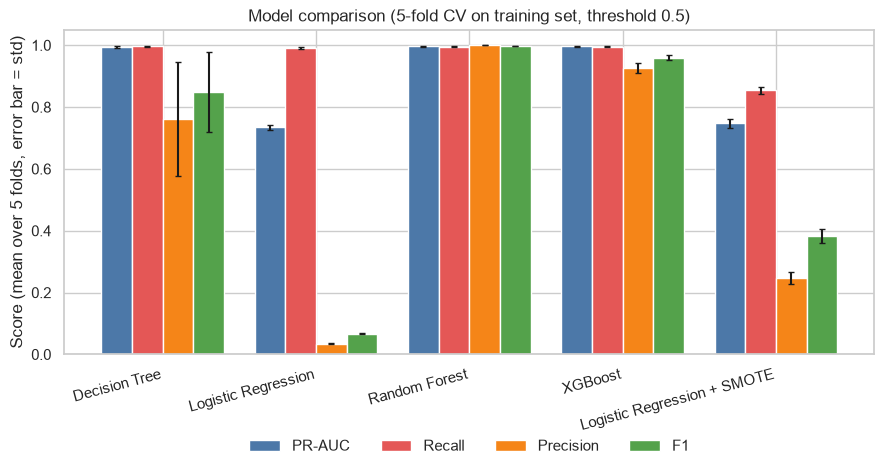

In [8]:
plot_df = cv_df[~cv_df.model.str.startswith("Dummy")].set_index("model")
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(plot_df))
w = 0.2
for i, (m, c, label) in enumerate([("pr_auc", "#4C78A8", "PR-AUC"), ("recall", "#E45756", "Recall"),
                                   ("precision", "#F58518", "Precision"), ("f1", "#54A24B", "F1")]):
    ax.bar(x + (i - 1.5) * w, plot_df[m + "_mean"], w, yerr=plot_df[m + "_std"], label=label, color=c, capsize=2)
ax.set_xticks(x)
ax.set_xticklabels(plot_df.index, rotation=15, ha="right")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score (mean over 5 folds, error bar = std)")
ax.set_title("Model comparison (5-fold CV on training set, threshold 0.5)")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.22), frameon=False)
plt.tight_layout()
plt.savefig("figures/07_model_comparison.png", dpi=150)
plt.show()

**Nhận xét:**
- Mô hình "đoán toàn 0" (Dummy) có accuracy ≈ 0.999 nhưng Recall = 0 → xác nhận Accuracy vô nghĩa.
- Logistic Regression bắt được nhiều gian lận nhưng Precision gần 0 (báo động nhầm rất nhiều).
- **Random Forest và XGBoost** dẫn đầu rõ rệt; hai mô hình này gần ngang nhau (chênh lệch nằm trong độ dao động giữa các fold).

## 4. Tuning mô hình tốt nhất
Chọn mô hình có PR-AUC cao nhất ở mục 3 rồi dùng `GridSearchCV` thử nhiều bộ siêu tham số (hyperparameter) bằng chính 5-fold CV đó.

⏱️ Bước này mất khoảng **7–8 phút**.

In [9]:
cand = cv_df[~cv_df.model.str.startswith("Dummy")].sort_values("pr_auc_mean", ascending=False)
best_name = cand.iloc[0]["model"]
print("Mô hình tốt nhất trước tuning:", best_name)

grids = {
    "Decision Tree": {"clf__max_depth": [4, 8, 12], "clf__min_samples_leaf": [1, 5, 20]},
    "Logistic Regression": {"clf__C": [0.1, 1, 10]},
    "Logistic Regression + SMOTE": {"clf__C": [0.1, 1, 10]},
    "Random Forest": {"clf__n_estimators": [200, 400], "clf__max_depth": [None, 12], "clf__min_samples_leaf": [1, 3]},
    "XGBoost": {"clf__n_estimators": [100, 300], "clf__max_depth": [3, 5], "clf__learning_rate": [0.05, 0.1],
                "clf__scale_pos_weight": [10.0, neg_pos]},
}
gs = GridSearchCV(models[best_name], grids[best_name], cv=cv, scoring="average_precision", n_jobs=1, refit=True, verbose=0)
t0 = time.time()
gs.fit(X_train, y_train)
print("Best params:", gs.best_params_)
print("CV PR-AUC  :", round(gs.best_score_, 4), f"({time.time() - t0:.0f}s)")

results["tuning"] = {
    "model": best_name,
    "grid": {k: [float(v) if isinstance(v, (int, float, np.floating)) else v for v in vs] for k, vs in grids[best_name].items()},
    "best_params": {k: (float(v) if isinstance(v, (int, float, np.floating)) else v) for k, v in gs.best_params_.items()},
    "best_cv_pr_auc": float(gs.best_score_),
    "n_candidates": int(len(gs.cv_results_["params"])),
}
final_model = gs.best_estimator_

pd.DataFrame(gs.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]].sort_values("rank_test_score")

Mô hình tốt nhất trước tuning: XGBoost
Best params: {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 300, 'clf__scale_pos_weight': 10.0}
CV PR-AUC  : 0.9974 (1456s)


,params,mean_test_score,std_test_score,rank_test_score
2,"{'clf__learning_rate': 0.05, 'clf__max_depth':...",0.997427,0.001528,1
12,"{'clf__learning_rate': 0.1, 'clf__max_depth': ...",0.997252,0.001365,2
10,"{'clf__learning_rate': 0.1, 'clf__max_depth': ...",0.997163,0.001494,3
8,"{'clf__learning_rate': 0.1, 'clf__max_depth': ...",0.997106,0.001648,4
6,"{'clf__learning_rate': 0.05, 'clf__max_depth':...",0.997051,0.001419,5
15,"{'clf__learning_rate': 0.1, 'clf__max_depth': ...",0.996941,0.001576,6
14,"{'clf__learning_rate': 0.1, 'clf__max_depth': ...",0.996926,0.001398,7
7,"{'clf__learning_rate': 0.05, 'clf__max_depth':...",0.996901,0.001562,8
13,"{'clf__learning_rate': 0.1, 'clf__max_depth': ...",0.996805,0.001784,9
11,"{'clf__learning_rate': 0.1, 'clf__max_depth': ...",0.996665,0.002186,10


## 5. Chọn ngưỡng quyết định (threshold)
Mô hình trả về **xác suất gian lận**. Ta phải chọn ngưỡng: xác suất ≥ ngưỡng thì cảnh báo.
- Ngưỡng thấp → bắt nhiều gian lận hơn nhưng báo động nhầm nhiều hơn.
- Ngưỡng cao → ít báo động nhầm nhưng bỏ sót nhiều hơn.

Ta chọn ngưỡng cho **F1 cao nhất** trên dự đoán *out-of-fold* của tập train (mỗi giao dịch được dự đoán bởi mô hình chưa từng thấy nó). **Tập test không được dùng ở bước này.**

Ngưỡng cho F1 tối ưu       : 0.8913
Ngưỡng cho Recall >= 0.90  : 0.9976


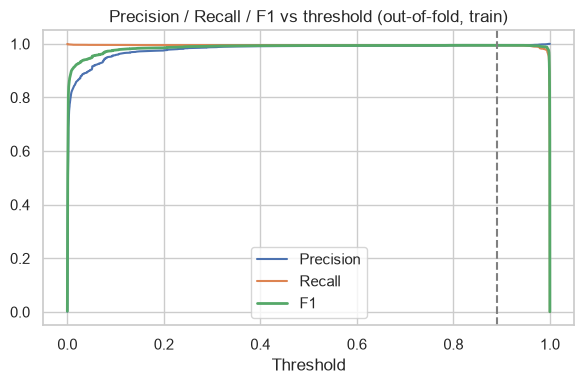

In [10]:
oof = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
thr_f1 = float(thr[np.argmax(f1s)])
ok = np.where(rec[:-1] >= 0.90)[0]
thr_recall90 = float(thr[ok[np.argmax(prec[:-1][ok])]]) if len(ok) else thr_f1

results["thresholds"] = {"f1_optimal": thr_f1, "recall_90": thr_recall90,
                         "oof_pr_auc": float(average_precision_score(y_train, oof))}
print("Ngưỡng cho F1 tối ưu       :", round(thr_f1, 4))
print("Ngưỡng cho Recall >= 0.90  :", round(thr_recall90, 4))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(thr, prec[:-1], label="Precision")
ax.plot(thr, rec[:-1], label="Recall")
ax.plot(thr, f1s, label="F1", lw=2)
ax.axvline(thr_f1, color="gray", ls="--")
ax.set_xlabel("Threshold")
ax.set_title("Precision / Recall / F1 vs threshold (out-of-fold, train)")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Đánh giá trên tập test (dữ liệu chưa từng thấy)
Đây là lần **duy nhất** dùng tập test. Kết quả cho ta ước lượng hiệu năng thực tế.

⚠️ Tập test chỉ có **29 vụ gian lận**, nên mỗi con số ở đây có độ bất định lớn: chỉ cần bỏ sót thêm 1 vụ thì Recall giảm khoảng 3.4 điểm phần trăm.

In [11]:
proba_test = final_model.predict_proba(X_test)[:, 1]


def eval_at(th):
    pred = (proba_test >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {
        "threshold": float(th), "accuracy": float(accuracy_score(y_test, pred)),
        "precision": float(precision_score(y_test, pred, zero_division=0)),
        "recall": float(recall_score(y_test, pred)), "f1": float(f1_score(y_test, pred)),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }


results["test"] = {
    "pr_auc": float(average_precision_score(y_test, proba_test)),
    "roc_auc": float(roc_auc_score(y_test, proba_test)),
    "at_default_0.5": eval_at(0.5),
    "at_f1_threshold": eval_at(thr_f1),
    "at_recall90_threshold": eval_at(thr_recall90),
}
print(json.dumps(results["test"], indent=2))

pred_final = (proba_test >= thr_f1).astype(int)
print(classification_report(y_test, pred_final, target_names=["Normal", "Fraud"], digits=4))
results["test_classification_report"] = classification_report(
    y_test, pred_final, target_names=["normal", "fraud"], output_dict=True)

# Dummy trên test, để minh họa "bẫy accuracy"
dummy = models["Dummy (always 0)"].fit(X_train, y_train)
results["test_dummy_accuracy"] = float(accuracy_score(y_test, dummy.predict(X_test)))
print("Accuracy của Dummy trên test:", round(results["test_dummy_accuracy"], 5))

{
  "pr_auc": 0.9976965138843399,
  "roc_auc": 0.9996875062083719,
  "at_default_0.5": {
    "threshold": 0.5,
    "accuracy": 0.9999724956071555,
    "precision": 0.982593037214886,
    "recall": 0.9963481436396835,
    "f1": 0.989422786340284,
    "tn": 1270852,
    "fp": 29,
    "fn": 6,
    "tp": 1637
  },
  "at_f1_threshold": {
    "threshold": 0.8913092613220215,
    "accuracy": 0.9999748531265422,
    "precision": 0.9843656043295249,
    "recall": 0.9963481436396835,
    "f1": 0.9903206291591047,
    "tn": 1270855,
    "fp": 26,
    "fn": 6,
    "tp": 1637
  },
  "at_recall90_threshold": {
    "threshold": 0.9976366758346558,
    "accuracy": 0.9997587471827644,
    "precision": 1.0,
    "recall": 0.8131466828971394,
    "f1": 0.8969452836522323,
    "tn": 1270881,
    "fp": 0,
    "fn": 307,
    "tp": 1336
  }
}
              precision    recall  f1-score   support

      Normal     1.0000    1.0000    1.0000   1270881
       Fraud     0.9844    0.9963    0.9903      1643

    a

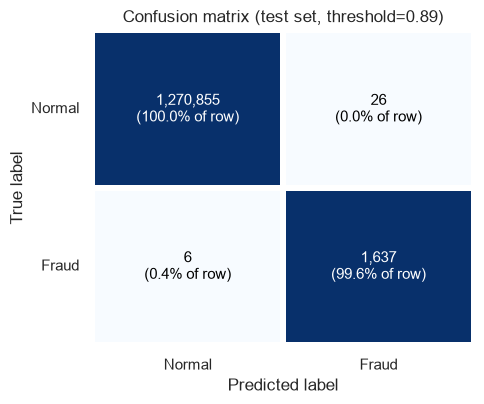

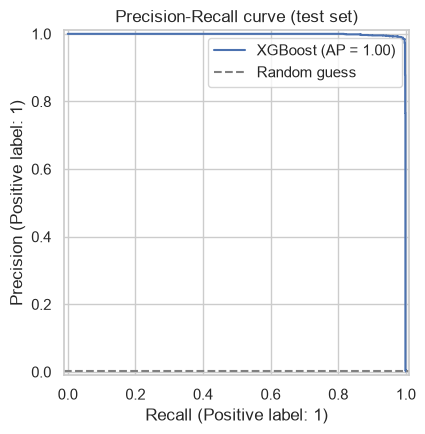

In [12]:
# Confusion matrix: màu theo tỷ lệ trong hàng, số trong ô là số giao dịch thật
cm = confusion_matrix(y_test, pred_final)
norm = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(5, 4.2))
sns.heatmap(norm, annot=False, cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax, linewidths=3, linecolor="white")
for i in range(2):
    for j in range(2):
        ax.text(j + 0.5, i + 0.5, f"{cm[i, j]:,}\n({norm[i, j]:.1%} of row)", ha="center", va="center",
                fontsize=11, color="white" if norm[i, j] > 0.5 else "black")
ax.set_xticklabels(["Normal", "Fraud"])
ax.set_yticklabels(["Normal", "Fraud"], rotation=0)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title(f"Confusion matrix (test set, threshold={thr_f1:.2f})")
plt.tight_layout()
plt.savefig("figures/08_confusion_matrix.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
PrecisionRecallDisplay.from_predictions(y_test, proba_test, ax=ax, name=best_name)
ax.axhline(y_test.mean(), color="gray", ls="--", label="Random guess")
ax.legend()
ax.set_title("Precision-Recall curve (test set)")
plt.tight_layout()
plt.savefig("figures/09_pr_curve.png", dpi=150)
plt.show()

## 7. Mô hình đã học được gì? (feature importance)

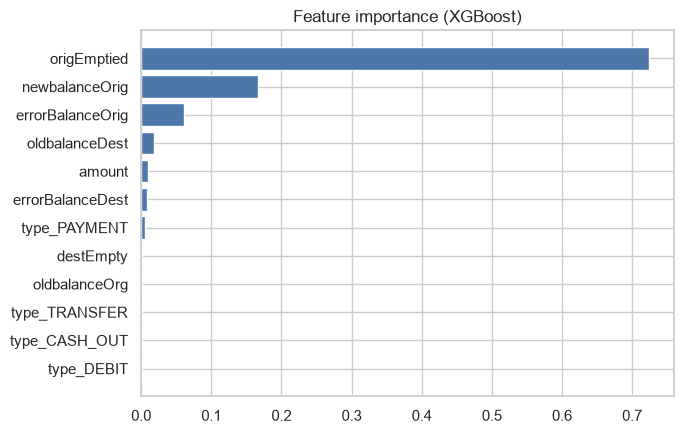

origEmptied         0.724
newbalanceOrig      0.166
errorBalanceOrig    0.062
oldbalanceDest      0.018
amount              0.010
errorBalanceDest    0.008
type_PAYMENT        0.005
destEmpty           0.002
dtype: float64

In [13]:
clf = final_model.named_steps["clf"]
names = [n.split("__", 1)[1] for n in final_model.named_steps["pre"].get_feature_names_out()]
imp = clf.feature_importances_ if hasattr(clf, "feature_importances_") else np.abs(clf.coef_[0])
order = np.argsort(imp)[::-1][:12]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(np.array(names)[order][::-1], np.array(imp)[order][::-1], color="#4C78A8")
ax.set_title(f"Feature importance ({best_name})")
plt.tight_layout()
plt.savefig("figures/10_feature_importance.png", dpi=150)
plt.show()
results["feature_importance"] = {names[i]: float(imp[i]) for i in order}
pd.Series(results["feature_importance"]).round(3).head(8)

Các đặc trưng ta tự tạo từ EDA (`errorBalanceOrig`, `origEmptied`) đứng đầu → mô hình đã học đúng "dấu vân tay" gian lận: rút sạch tài khoản gửi và số dư không khớp.

## 8. Phân tích lỗi
Xem những vụ gian lận bị bỏ sót (false negative) và các cảnh báo nhầm (false positive).

In [14]:
err = X_test.copy()
err["isFraud"] = y_test.values
err["proba"] = proba_test

missed = err[(err.isFraud == 1) & (proba_test < thr_f1)]
results["missed_fraud"] = missed.round(2).reset_index(drop=True).to_dict(orient="records")
fp_df = err[(err.isFraud == 0) & (proba_test >= thr_f1)]
results["false_positives_sample"] = fp_df.head(5).round(2).reset_index(drop=True).to_dict(orient="records")

print(f"Bỏ sót {len(missed)} vụ gian lận; cảnh báo nhầm {len(fp_df)} giao dịch.")
display(missed.round(2))

Bỏ sót 6 vụ gian lận; cảnh báo nhầm 26 giao dịch.


,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,proba
77745,CASH_OUT,277970.88,0.00,0.0,0.00,277970.88,1,0.04
6362585,CASH_OUT,0.00,0.00,0.0,267522.87,267522.87,1,0.32
543928,CASH_OUT,23292.30,0.00,0.0,392364.62,415656.92,1,0.00
217978,TRANSFER,123194.95,79466.45,0.0,535933.16,263908.84,1,0.00
6351226,CASH_OUT,0.00,0.00,0.0,107777.02,107777.02,1,0.32
14861,CASH_OUT,181728.11,0.00,0.0,11397.00,184477.77,1,0.00


Vụ bị bỏ sót là một TRANSFER rất lớn **không** rút sạch tài khoản gửi, khác với kiểu gian lận phổ biến trong dữ liệu (chỉ khoảng 9 trong 147 vụ có kiểu này), nên mô hình có rất ít ví dụ để học.

## 9. Lưu mô hình để deploy
Lưu **cả pipeline** (đặc trưng + one-hot + scaler + mô hình) bằng `joblib`, cùng file `metadata.json` chứa ngưỡng và danh sách cột.

In [15]:
joblib.dump(final_model, "model/fraud_pipeline.joblib")
meta = {
    "model_name": best_name,
    "best_params": results["tuning"]["best_params"],
    "threshold_f1": thr_f1,
    "threshold_recall90": thr_recall90,
    "raw_columns": RAW_COLUMNS,
    "types": sorted(df["type"].unique().tolist()),
    "test_metrics_at_f1_threshold": results["test"]["at_f1_threshold"],
}
with open("model/metadata.json", "w", encoding="utf-8") as fh:
    json.dump(meta, fh, ensure_ascii=False, indent=2)
with open("results.json", "w", encoding="utf-8") as fh:
    json.dump(results, fh, ensure_ascii=False, indent=2, default=str)
print("Đã lưu model/fraud_pipeline.joblib, model/metadata.json, results.json")

Đã lưu model/fraud_pipeline.joblib, model/metadata.json, results.json


➡️ Tiếp tục với `03_Deployment_Check.ipynb`.